# Bank GoodCredit – Credit Risk Scoring (PM-PR-0015)

**Goal.** Predict a credit-worthiness score for current credit-card customers and flag customers likely to fall into the **30+ DPD bucket** (`Bad_label = 1`), so the bank can reduce credit-default risk.
The bank's benchmark model has a **Gini of 37.9** and a rank-ordering curve that runs from a 1.3 % bad rate (decile 1) to 11.7 % (decile 10).

**Deliverables requested by the project brief**

| # | Deliverable | Where |
|---|---|---|
| 1 | Data exploration insights – what was found and what decision was taken | Sections 1 and 2 |
| 2 | Feature matrix – selected features with gain | Section 5 |
| 3 | Model evaluation – Gini and rank ordering | Sections 4 and 6 |

---
### Results at a glance

* **Data:** all three tables, 23,896 customers (1,004 bad, 4.2 %), 186,329 account rows and 413,188 enquiry rows. Every customer is covered by every table.
* **Cross-validated Gini of the final ensemble: 36.8** (bootstrap 95 % interval 33.8 to 40.1) versus the benchmark of **37.9**. The difference of 1.1 points is smaller than the ±1.9 standard error, so **the model matches the benchmark within noise but does not clearly beat it.** About 26 % of bootstrap draws exceed 37.9.
* **Out-of-time Gini: 33.9 ± 3.3** (train before 1 Nov 2015, test after), about 3 points below cross-validation, which points to some drift between vintages.
* **Rank ordering:** bad rate rises from **1.0 %** (decile 1) to **10.5 %** (decile 10). The riskiest 30 % of customers hold 56 % of all bads. Only 1 of 9 decile steps is out of order (deciles 5–6, 3.52 % vs 3.39 %).
* **Feature matrix:** **30 features** out of 84 candidates. Account features now carry real weight (Section 5); 11 of the brief's 12 suggested features are in the final model.
* **Open items:** two enquiry-code assumptions to confirm with the bank, and an out-of-time check on newer data before use (Section 7).

## Setup

The notebook looks for `Cust_Demographics.csv`, `Cust_Enquiry.csv` and `Cust_Account.csv` (case-insensitive) in `DATA_DIR` (set in the first code cell), the working folder, `./data`, `~/Downloads` or `/mnt/user-data/uploads`. Database credentials are **not** stored here; a commented-out block shows how to read the tables from MySQL using environment variables.

In [1]:
import os, glob, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata, skew
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

SEED = 42
BENCHMARK_GINI = 37.9                      # from the project brief
# benchmark decile bad rates from the brief; decile 1 = safest ... decile 10 = riskiest
BENCHMARK_DECILES = [0.01317716, 0.0204978, 0.0204978, 0.02052786, 0.03660322,
                     0.04245974, 0.03958944, 0.06002928, 0.08052709, 0.11713031]
MIN_COVERAGE = 0.10                        # a bureau feature must be populated for >= 10 % of customers
CORR_THRESHOLD = 0.95                      # drop one of each pair with |Spearman| above this
N_REPEATS, N_FOLDS = 2, 5                  # repeated stratified CV
RESULTS = {}

# Optional: put the folder holding the three CSV files here (None = search the usual places)
DATA_DIR = None


In [2]:
def find_file(name):
    """Case-insensitive lookup of an exact file name in DATA_DIR and the usual folders."""
    filename = os.path.basename(name).lower()
    folders = [DATA_DIR, ".", "data", os.path.expanduser("~/Downloads"), "/mnt/user-data/uploads"]
    for folder in folders:
        if folder and os.path.isdir(folder):
            for f in glob.glob(os.path.join(folder, "*")):
                if os.path.basename(f).lower() == filename:
                    return f
    return None


In [3]:
def load_required(name):
    p = find_file(name)
    if p is None:
        raise FileNotFoundError(f"{name} not found - set DATA_DIR in the first code cell")
    return pd.read_csv(p, low_memory=False)

demo = load_required("Cust_Demographics.csv")
enq  = load_required("Cust_Enquiry.csv")
acct_path = find_file("Cust_Account.csv")
acct = pd.read_csv(acct_path, low_memory=False) if acct_path else None
ACCOUNT_AVAILABLE = acct is not None

# --- Optional: pull the FULL tables from the bank's MySQL database instead of CSV files ---
# Credentials are deliberately NOT stored in this notebook; put them in environment variables.
# import sqlalchemy as sa
# eng = sa.create_engine(f"mysql+pymysql://{os.environ['DB_USER']}:{os.environ['DB_PASS']}@{os.environ['DB_HOST']}:3306/project_banking")
# acct, enq, demo = [pd.read_sql(f"select * from {t}", eng) for t in ["Cust_Account", "Cust_Enquiry", "Cust_Demographics"]]

DATE_FMT = "%d-%b-%y"
demo["app_dt"] = pd.to_datetime(demo["dt_opened"], format=DATE_FMT)   # application date = reference date for every feature
print({"Cust_Demographics": demo.shape, "Cust_Enquiry": enq.shape, "Cust_Account": None if acct is None else acct.shape})
if not ACCOUNT_AVAILABLE:
    print("WARNING: Cust_Account.csv was not found - the account (tradeline) features are skipped in this run.")
demo.iloc[:5, :14]

{'Cust_Demographics': (23896, 84), 'Cust_Enquiry': (413188, 6), 'Cust_Account': (186329, 21)}


,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11
0,18-Apr-15,1,13-Apr-15,Insignia,13-Apr-15,650.0,2.0,Card Setup,14.0,500000.0,NaN,NaN,NaN,Y
1,21-Apr-15,2,21-Apr-15,Insignia,21-Apr-15,760.0,1.0,Card Setup,14.0,1200000.0,NaN,NaN,NaN,Y
2,22-Apr-15,3,21-Apr-15,Insignia,21-Apr-15,774.0,1.0,Card Setup,14.0,700000.0,NaN,NaN,NaN,Y
3,25-Apr-15,4,15-Apr-15,Insignia,20-Apr-15,770.0,1.0,Card Setup,14.0,500000.0,NaN,NaN,NaN,Y
4,06-May-15,5,30-Apr-15,Insignia,NaN,NaN,3.0,Card Setup,14.0,500000.0,NaN,NaN,NaN,Y


## 1. Data exploration

### 1.1 How do the three tables fit together?
`Cust_Demographics` is the modelling table (one row per application, with the target `Bad_label`). `Cust_Enquiry` and `Cust_Account` (bureau tradelines) are one-to-many tables that must be aggregated to customer level before joining.

In [4]:
d_ids, e_ids = set(demo.customer_no), set(enq.customer_no)
rows = [("Cust_Demographics", len(demo), len(d_ids), len(d_ids)), ("Cust_Enquiry", len(enq), len(e_ids), len(e_ids & d_ids))]
if ACCOUNT_AVAILABLE:
    a_ids = set(acct.customer_no); rows.append(("Cust_Account", len(acct), len(a_ids), len(a_ids & d_ids)))
overview = pd.DataFrame(rows, columns=["table", "rows", "unique customers", "customers also in Demographics"]).set_index("table")
overview["% of demographics customers covered"] = (100 * overview["customers also in Demographics"] / len(d_ids)).round(1)
display(overview)

print("Duplicate customer_no in demographics:", int(demo.customer_no.duplicated().sum()))
chk = enq.merge(demo[["customer_no", "dt_opened"]], on=["customer_no", "dt_opened"])
print("Enquiry rows matching on (customer_no, dt_opened): %d of %d" % (len(chk), len(enq)))
print("Enquiries per customer: median %.0f, mean %.1f, max %d" % tuple([enq.groupby("customer_no").size().median(), enq.groupby("customer_no").size().mean(), enq.groupby("customer_no").size().max()]))

,rows,unique customers,customers also in Demographics,% of demographics customers covered
table,,,,
Cust_Demographics,23896,23896,23896,100.0
Cust_Enquiry,413188,23896,23896,100.0
Cust_Account,186329,23896,23896,100.0


Duplicate customer_no in demographics: 0
Enquiry rows matching on (customer_no, dt_opened): 413188 of 413188
Enquiries per customer: median 13, mean 17.3, max 308


**Finding.** All three tables cover all 23,896 customers: 186,329 account rows (no account reported after its application date) and 413,188 enquiry rows (median 13 per customer), and every row matches its customer on `(customer_no, dt_opened)`. There are no duplicate customers. (Enquiry *features* exist for 23,787 customers: 110 enquiry rows have unparseable dates and are ignored, which leaves 109 customers with no usable enquiry history; their enquiry features are imputed.)

**Decision.** Both bureau tables are aggregated to one row per customer using the brief's feature definitions, with every look-back anchored to the application date.

### 1.2 Target variable

Customers: 23896 | Bad: 1004 | Good: 22892 | Bad rate: 4.20%
Approximate standard error of a Gini measured on this many customers: +/- 1.9 points


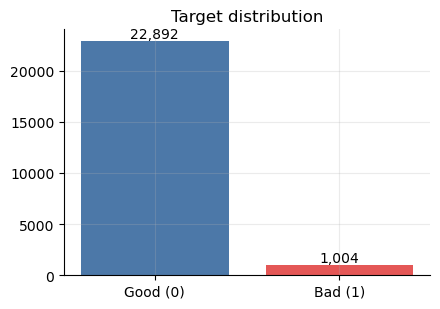

In [5]:
y_all = demo["Bad_label"].astype(int)
n, n_bad = len(y_all), int(y_all.sum())
print("Customers: %d | Bad: %d | Good: %d | Bad rate: %.2f%%" % (n, n_bad, n - n_bad, 100 * n_bad / n))

def auc_se(auc, n_pos, n_neg):
    # Hanley & McNeil (1982) standard error of the AUC
    q1, q2 = auc / (2 - auc), 2 * auc ** 2 / (1 + auc)
    return np.sqrt((auc * (1 - auc) + (n_pos - 1) * (q1 - auc ** 2) + (n_neg - 1) * (q2 - auc ** 2)) / (n_pos * n_neg))

# Gini = 2*AUC - 1, so SE(Gini) = 2*SE(AUC); evaluated at the benchmark Gini of 37.9 (AUC 0.6895)
se = 200 * auc_se((BENCHMARK_GINI / 100 + 1) / 2, n_bad, n - n_bad)
RESULTS.update(n_rows=n, n_bad=n_bad, gini_se=se)
print("Approximate standard error of a Gini measured on this many customers: +/- %.1f points" % se)

fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.bar(["Good (0)", "Bad (1)"], [n - n_bad, n_bad], color=["#4C78A8", "#E45756"])
for i, v in enumerate([n - n_bad, n_bad]): ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_title("Target distribution"); plt.tight_layout(); plt.show()

**Finding.** 1,004 bad customers (**4.2 %**): imbalanced, but with enough events for a stable model. A Gini measured on this sample has a standard error of about **±1.9 points**, so a gap of several points to the benchmark is meaningful. Because of the imbalance I use *stratified* folds and report Gini (rank-based) rather than accuracy.

### 1.3 Does the bad rate change with application month (vintage)?

,customers,bads,bad_rate_%
month,,,
2015-04,259,7,2.70
2015-05,1438,36,2.50
2015-06,2272,78,3.43
2015-07,2775,116,4.18
2015-08,2613,99,3.79
2015-09,3137,156,4.97
2015-10,3686,183,4.96
2015-11,3716,173,4.66
2015-12,4000,156,3.90


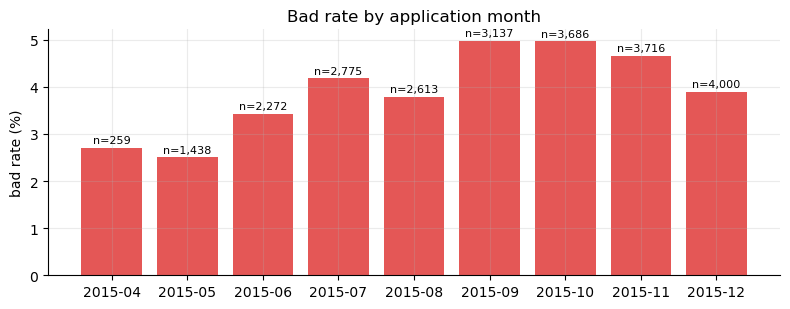

Application period: 2015-04-16 to 2015-12-31


In [6]:
vint = (demo.assign(month=demo.app_dt.dt.to_period("M").astype(str))
            .groupby("month").Bad_label.agg(customers="size", bads="sum", bad_rate="mean"))
display(vint.assign(bad_rate=(vint.bad_rate * 100).round(2)).rename(columns={"bad_rate": "bad_rate_%"}))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(vint.index, vint.bad_rate * 100, color="#E45756")
for i, (r, c) in enumerate(zip(vint.bad_rate * 100, vint.customers)): ax.text(i, r + 0.1, f"n={c:,}", ha="center", fontsize=8)
ax.set_ylabel("bad rate (%)"); ax.set_title("Bad rate by application month"); plt.tight_layout(); plt.show()
print("Application period: %s to %s" % (demo.app_dt.min().date(), demo.app_dt.max().date()))

**Finding.** Applications run from April to December 2015. The bad rate climbs from about 2.5 % in April–May (small months, 259 and 1,438 customers) to roughly 5 % in September–October, then eases to 3.9 % in December. Later vintages are bigger, so the sample is dominated by H2 2015.

**Decision.** `dt_opened` is **not a model feature**: a calendar month would not generalise to future applications. It is used only as the reference date for ages, tenures and look-backs, and to build an **out-of-time** test (train before 1 Nov 2015, test from 1 Nov 2015) in Section 4.4.

### 1.4 Audit of the 79 anonymised demographic features
For each feature I look at type, number of distinct values, missing share and sample values, then decide what to do with it.

In [7]:
feat_cols = [f"feature_{i}" for i in range(1, 80)]
raw = demo[feat_cols]
def is_num(s): return pd.api.types.is_numeric_dtype(s)

audit = pd.DataFrame({
    "dtype": ["numeric" if is_num(raw[c]) else "text" for c in feat_cols],
    "n_unique": [raw[c].nunique() for c in feat_cols],
    "missing_%": [round(100 * raw[c].isna().mean(), 1) for c in feat_cols],
    "examples": [", ".join(map(str, raw[c].dropna().unique()[:3])) for c in feat_cols],
}, index=feat_cols)

const  = audit.index[audit.n_unique <= 1].tolist()
sparse = audit.index[(audit["missing_%"] >= 95) & (audit.n_unique > 1)].tolist()
dups = [(a, b) for i, a in enumerate(feat_cols) for b in feat_cols[i + 1:] if raw[a].astype(str).equals(raw[b].astype(str))]
print("Constant / empty features (%d):" % len(const), const)
print("Features >= 95%% missing, not constant (%d):" % len(sparse), sparse)
print("Exact duplicate pairs:", dups)
print("feature_63 is the birth year of feature_30 with '-0' appended: %.1f%% of rows" % (100 * (raw.feature_63 == raw.feature_30.astype("Int64").astype(str) + "-0").mean()))
print("feature_75 is the '0000-00-00' placeholder in %.1f%% of rows (other values use mixed date formats)" % (100 * (raw.feature_75 == "0000-00-00").mean()))
print("feature_70 is the '0-0' placeholder in %.1f%% of rows" % (100 * (raw.feature_70 == "0-0").mean()))
print("feature_54 holds the single value %s on every row - a date AFTER every application (extraction date)" % raw.feature_54.iloc[0])
print("feature_3 range: %d to %d (-1 appears %d times; looks like a bureau score with -1 = no score)" % (raw.feature_3.min(), raw.feature_3.max(), (raw.feature_3 == -1).sum()))

# decision-process columns: feature_8 / feature_9 hold rejection / verification-failure reasons
print("\nfeature_9 levels (rejection / verification reasons, %.1f%% missing):" % audit.loc["feature_9", "missing_%"])
print(raw.feature_9.value_counts().head(8).to_string())
audit.sort_values("missing_%", ascending=False).head(12)

Constant / empty features (3): ['feature_5', 'feature_6', 'feature_54']
Features >= 95% missing, not constant (6): ['feature_10', 'feature_17', 'feature_18', 'feature_49', 'feature_61', 'feature_74']
Exact duplicate pairs: [('feature_11', 'feature_59'), ('feature_34', 'feature_68'), ('feature_35', 'feature_69')]
feature_63 is the birth year of feature_30 with '-0' appended: 89.2% of rows
feature_75 is the '0000-00-00' placeholder in 99.7% of rows (other values use mixed date formats)
feature_70 is the '0-0' placeholder in 76.3% of rows
feature_54 holds the single value 17-Jun-16 on every row - a date AFTER every application (extraction date)
feature_3 range: -1 to 896 (-1 appears 6 times; looks like a bureau score with -1 = no score)

feature_9 levels (rejection / verification reasons, 94.7% missing):
feature_9
Negative Office Tele Verification        336
Contactability Failure at Office         275
Negative Mobile tele Verification        249
Contactability Failure at Residence      1

,dtype,n_unique,missing_%,examples
feature_61,text,8,100.0,"GNWX-B, 229766, 500034"
feature_74,numeric,3,99.9,"3.0, 4.0, 2.0"
feature_18,text,12,99.9,"91, 180, 4539"
feature_10,text,7,99.8,"3.09E+11, 1.01E+15, 3.07E+11"
feature_49,numeric,18,99.6,"309000000000.0, 1676840.0, 1650139.0"
feature_17,text,302,95.7,"4284, 4077, 5107"
feature_8,text,19,94.7,"RNOI, RMIC, RCFO"
feature_9,text,19,94.7,"Not Interested, Minimum Income Requirement Not Met - VI ..."
feature_57,text,2,90.0,"Y, N"
feature_73,text,2,87.7,"Y, N"


**Findings from the audit and the decision taken for each**

| Issue found | Features | Decision |
|---|---|---|
| Constant values (no information) | `feature_5, 6, 54` | **Drop.** `feature_54` is also a date *after* every application (extraction date), a potential leak. |
| ≥ 95 % missing | `feature_10, 17, 18, 49, 61, 74` | **Drop** – too few populated rows to support a split. |
| Rejection / verification-failure reasons (94.7 % missing) | `feature_8, 9` | **Drop.** These record why an application failed a check, i.e. information produced *during* application processing, which would not exist when scoring a new applicant. |
| Exact duplicates | `11=59`, `34=68`, `35=69` | **Keep one** of each pair. |
| Birth year repeated as text | `feature_63` (equals `feature_30` + "-0" in 89 % of rows) | **Drop**; age is derived from `feature_21`. |
| Masked identifiers (PAN, mobile) | `feature_20, 22, 47, 77` | **Drop** – identifiers carry no risk signal. |
| Placeholder-ridden / mixed date formats | `feature_70, 75` (76 % and 99.7 % placeholders) | **Drop.** |
| True dates | `feature_2, 21, 53` | **Convert** to *days before application*, *age*, *tenure*. |
| Years stored as integers (0 = unknown) | `feature_39` | Convert to *years since*, 0 → missing. |
| Branch / pincode / designation codes with hundreds of levels | `15, 16, 17, 29, 38, 44, 66` (`feature_17` also appears in the sparse group above) | **Drop** – they memorise rather than generalise. |
| City / bank names with 18–70 levels | `28, 43, 48, 51` | **Frequency-encode.** |
| ≤ 16 levels | most other text columns | **One-hot encode**, missing becomes its own level. |
| E-mail domains | `feature_24, 45` | **Derive** `is_free_email` and `has_office_email` flags. |
| `feature_3` uses `-1` for "no score" (6 rows) | `feature_3` | Convert `-1` → missing. |

The next section implements these decisions.

## 2. Feature engineering

### 2.1 Demographic features (cleaning decisions from 1.4 turned into code)
Everything is computed relative to each customer's **application date**, so no information from after the application can leak in.

In [8]:
decisions = []                       # running log of every feature decision: (feature, stage, reason)
def log(feats, stage, reason):
    for f in ([feats] if isinstance(feats, str) else feats): decisions.append((f, stage, reason))

CONSTANT    = [c for c in feat_cols if raw[c].nunique() <= 1]
VERY_SPARSE = [c for c in feat_cols if raw[c].isna().mean() >= 0.95 and c not in CONSTANT]
PROCESS     = ["feature_8", "feature_9"]                                  # rejection / verification-failure reasons (decision process)
PII         = ["feature_20", "feature_22", "feature_47", "feature_77"]    # masked PAN / mobile numbers
HIGH_CARD   = ["feature_15", "feature_16", "feature_17", "feature_29", "feature_38", "feature_44", "feature_66"]  # branch / pincode / designation
MESSY       = ["feature_70", "feature_75"]
DUPLICATE   = ["feature_59", "feature_68", "feature_69", "feature_63"]    # copies of 11, 34, 35, 30
DERIVED     = ["feature_2", "feature_21", "feature_53", "feature_39", "feature_24", "feature_45"]
FREQ_ENC    = ["feature_28", "feature_43", "feature_48", "feature_51"]    # city / bank names with 18-70 levels

log(CONSTANT, "dropped (audit)", "constant / empty"); log(VERY_SPARSE, "dropped (audit)", ">= 95% missing")
log(PROCESS, "dropped (audit)", "decision-process reason, 95% missing")
log(PII, "dropped (audit)", "masked identifier"); log(HIGH_CARD, "dropped (audit)", "branch / pincode / designation code with many levels")
log(MESSY, "dropped (audit)", "placeholder-ridden / inconsistent format"); log(DUPLICATE, "dropped (audit)", "exact duplicate of another feature")
log(["feature_30"], "dropped (audit)", "replaced by age derived from feature_21")

def parse_dt(s): return pd.to_datetime(s, format=DATE_FMT, errors="coerce")
def fix_century(dt, ref):
    # %y maps '65' to 2065; anything later than the application date must really be 19xx
    dt = dt.copy(); m = dt > ref
    dt[m] = dt[m] - pd.DateOffset(years=100)
    return dt
ref = demo["app_dt"]

X = pd.DataFrame(index=demo.index)
X["days_entry_to_application"] = (ref - parse_dt(demo["entry_time"])).dt.days
X["f2_days_before_application"] = (ref - parse_dt(raw["feature_2"])).dt.days
X["age_years"]                  = (ref - fix_century(parse_dt(raw["feature_21"]), ref)).dt.days / 365.25
X["f53_tenure_years"]           = (ref - fix_century(parse_dt(raw["feature_53"]), ref)).dt.days / 365.25
yrs = ref.dt.year - raw["feature_39"].where(raw["feature_39"] > 0)           # 0 means unknown
X["f39_years_since"]            = yrs.clip(lower=0)

FREE = {"@GMAIL.COM", "@YAHOO.COM", "@YAHOO.CO.IN", "@YAHOO.IN", "@HOTMAIL.COM", "@REDIFFMAIL.COM", "@VSNL.NET", "@VSNL.COM",
        "@OUTLOOK.COM", "@LIVE.COM", "@ROCKETMAIL.COM", "@AOL.COM"}
X["is_free_email"]    = raw["feature_24"].isin(FREE).astype(float).where(raw["feature_24"].notna())
X["has_office_email"] = raw["feature_45"].notna().astype(int)
log(DERIVED, "transformed", "date / year / e-mail converted to numeric features")

skip = set(CONSTANT + VERY_SPARSE + PROCESS + PII + HIGH_CARD + MESSY + DUPLICATE + DERIVED + ["feature_30"])
for c in feat_cols:
    if c in skip or not is_num(raw[c]): continue
    X[c] = raw[c]
X["feature_3"] = X["feature_3"].where(X["feature_3"] > 0)                       # -1 = no score

for c in feat_cols:
    if c in skip or is_num(raw[c]): continue
    s = raw[c]
    if c in FREQ_ENC:
        s2 = s.fillna("MISSING")
        X[c + "_freq"] = s2.map(s2.value_counts(normalize=True)).values
        log(c, "transformed", "frequency encoded")
    else:
        dm = pd.get_dummies(s.fillna("MISSING"), prefix=c, dtype=int)
        if dm.shape[1] == 2: dm = dm.iloc[:, [1]]                                 # binary -> one column
        X = pd.concat([X, dm], axis=1)
        log(c, "transformed", "one-hot encoded")

print("Engineered demographic columns:", X.shape[1])
X[["age_years", "f53_tenure_years", "f39_years_since", "days_entry_to_application", "f2_days_before_application"]].describe().round(1).T

Engineered demographic columns: 151


,count,mean,std,min,25%,50%,75%,max
age_years,23881.0,34.1,7.3,18.7,28.9,32.3,37.5,76.4
f53_tenure_years,12286.0,2.2,2.0,0.1,1.2,1.6,2.4,100.0
f39_years_since,18214.0,4.7,4.0,0.0,2.0,4.0,6.0,16.0
days_entry_to_application,23881.0,27.7,22.0,0.0,15.0,21.0,32.0,288.0
f2_days_before_application,21060.0,27.0,22.1,0.0,15.0,21.0,31.0,288.0


### 2.2 Enquiry features (bureau enquiries, definitions as suggested in the brief)
Only enquiries made **on or before** the application date are used (none were dated after it; 110 rows have an unparseable date and are ignored). Beyond the brief's features I add 30-day counts, minimum enquiry age, enquiry amounts and the share of enquiries in the last 90 days.

Two **assumptions** need confirming with the bank: (a) purpose codes `{0, 5, 6, 10, 12}` count as *unsecured / other* for `perc_unsecured_others` (the brief's remark says "secured", which looks like a typo); (b) code `10` (57.7 % of enquiries) is a credit-card enquiry, used for `max_freq_enquiry`.

In [9]:
e = enq.merge(demo[["customer_no", "app_dt"]], on="customer_no", how="inner")
e["enquiry_dt"] = parse_dt(e["enquiry_dt"])
e["days_before"] = (e["app_dt"] - e["enquiry_dt"]).dt.days
print("Enquiries dated AFTER the application date (excluded to avoid leakage):", int((e.days_before < 0).sum()))
print("Enquiries with unparseable date:", int(e.days_before.isna().sum()))
e = e[e.days_before >= 0]
print("\nEnquiry purpose codes (share of enquiries):")
print((e.enq_purpose.value_counts(normalize=True).head(10) * 100).round(1).to_string())

UNSECURED_OTHERS = {0, 5, 6, 10, 12}      # ASSUMPTION: bureau purpose codes for personal / consumer / credit card / overdraft / other
g = e.groupby("customer_no")
enq_feat = pd.DataFrame({
    "count_enquiry_recency_365":   g["days_before"].apply(lambda s: (s <= 365).sum()),
    "count_enquiry_recency_90":    g["days_before"].apply(lambda s: (s <= 90).sum()),
    "count_enquiry_recency_30":    g["days_before"].apply(lambda s: (s <= 30).sum()),
    "count_enquiry_total":         g.size(),
    "mean_diff_open_enquiry_dt":   g["days_before"].mean(),
    "min_diff_open_enquiry_dt":    g["days_before"].min(),
    "perc_unsecured_others":       g["enq_purpose"].apply(lambda s: s.isin(UNSECURED_OTHERS).mean()),
    "mean_enq_amt":                g["enq_amt"].mean(),
    "max_enq_amt":                 g["enq_amt"].max(),
    "max_freq_enquiry_purpose":    g["enq_purpose"].agg(lambda s: s.mode().iloc[0]),
})
enq_feat["max_freq_enquiry_is_credit_card"] = (enq_feat.pop("max_freq_enquiry_purpose") == 10).astype(int)
enq_feat["share_enq_last_90"] = enq_feat.count_enquiry_recency_90 / enq_feat.count_enquiry_total
enq_feat = enq_feat.reindex(demo["customer_no"]).set_index(demo.index)
print("\nCustomers with enquiry features:", int(enq_feat.count_enquiry_total.notna().sum()))
enq_feat.dropna().head()

Enquiries dated AFTER the application date (excluded to avoid leakage): 0
Enquiries with unparseable date: 110

Enquiry purpose codes (share of enquiries):
enq_purpose
10.0    57.7
5.0     19.8
1.0      5.7
6.0      4.2
2.0      3.8
0.0      3.6
13.0     2.7
51.0     1.0
3.0      0.4
7.0      0.3

Customers with enquiry features: 23787


,count_enquiry_recency_365,count_enquiry_recency_90,count_enquiry_recency_30,count_enquiry_total,mean_diff_open_enquiry_dt,min_diff_open_enquiry_dt,perc_unsecured_others,mean_enq_amt,max_enq_amt,max_freq_enquiry_is_credit_card,share_enq_last_90
0,1.0,0.0,0.0,18.0,1443.500000,120.0,0.944444,2.767306e+05,3500000.0,1.0,0.000000
1,19.0,2.0,0.0,68.0,812.485294,69.0,0.426471,9.818650e+07,750000000.0,0.0,0.029412
2,0.0,0.0,0.0,1.0,438.000000,438.0,0.000000,3.400000e+06,3400000.0,0.0,0.000000
3,0.0,0.0,0.0,34.0,1920.823529,418.0,0.470588,1.494412e+06,4000000.0,0.0,0.000000
4,0.0,0.0,0.0,2.0,1497.500000,1134.0,1.000000,1.000000e+03,1000.0,1.0,0.000000


### 2.3 Account (tradeline) features
`paymenthistory1` is a string of 3-character tokens, one per month: a number (days past due, e.g. `030`), `STD` (on time), `XXX` (no data) or a bureau status such as `SMA`, `SUB`, `DBT`, `LSS`. I assume the **most recent month comes first**. `SMA` is treated as 30 DPD; `SUB / DBT / LSS` as 90 DPD.

The brief's seven account-based features are built from these fields (DPD-bucket share, payment-timing gaps, months to first 30+ DPD, utilisation ratios, history length), plus the number of accounts. The cell reports 186,329 account rows joined with no row dated after the application.

In [10]:
def parse_hist(s):
    s = str(s).replace('"', "")
    out = []
    for i in range(0, len(s) - len(s) % 3, 3):
        t = s[i:i + 3]
        if t.isdigit():  out.append(int(t))
        elif t == "STD": out.append(0)
        elif t == "XXX": out.append(np.nan)
        elif t == "SMA": out.append(30)
        else:            out.append(90)
    return np.array(out, dtype=float)

if ACCOUNT_AVAILABLE:
    a = acct.merge(demo[["customer_no", "dt_opened", "app_dt"]], on=["customer_no", "dt_opened"], how="inner")
    for c in ["opened_dt", "last_paymt_dt", "reporting_dt"]: a[c] = parse_dt(a[c])
    print("Account rows joined to a demographics customer:", len(a), "| reported after application:", int((a.reporting_dt > a.app_dt).sum()))
    hist = a["paymenthistory1"].map(parse_hist)
    a["hist_len"]               = hist.map(len)
    a["share_dpd_0_29"]         = hist.map(lambda h: np.mean(h[~np.isnan(h)] < 30) if (~np.isnan(h)).any() else np.nan)
    a["months_to_first_30plus"] = hist.map(lambda h: next((i for i, v in enumerate(h) if v >= 30), len(h)))
    a["days_open_to_lastpay"]   = (a.last_paymt_dt - a.opened_dt).dt.days

    def agg_account(df):
        cl, cb, cash = df.creditlimit.sum(min_count=1), df.cur_balance_amt.sum(), df.cashlimit.mean()
        ratio = cb / cl if cl and cl > 0 else np.nan
        denom = df.creditlimit.mean() + (0 if np.isnan(cash) else cash)
        mean_ratio = df.cur_balance_amt.mean() / denom if denom and denom > 0 else np.nan
        return pd.Series({
            "payment_history_avg_dpd_0_29_bucket": df.share_dpd_0_29.mean(),
            "total_diff_lastpaymt_opened_dt":      df.days_open_to_lastpay.sum(min_count=1),
            "mean_diff_lastpaymt_opened_dt":       df.days_open_to_lastpay.mean(),
            "min_months_last_30_plus":             df.months_to_first_30plus.min(),
            "utilisation_trend":                   ratio / mean_ratio if mean_ratio and mean_ratio > 0 else np.nan,
            "Ratio_currbalance_creditlimit":       ratio,
            "payment_history_mean_length":         df.hist_len.mean(),
            "n_accounts":                          len(df),
        })
    acct_feat = a.groupby("customer_no").apply(agg_account).reindex(demo["customer_no"]).set_index(demo.index)
    print("Customers with account features:", int(acct_feat.n_accounts.notna().sum()))
else:
    acct_feat = pd.DataFrame(index=demo.index)
    print("Cust_Account.csv not available -> no account features in this run.")
acct_feat.dropna(how="all").round(3).head()

Account rows joined to a demographics customer: 186329 | reported after application: 0
Customers with account features: 23896


,payment_history_avg_dpd_0_29_bucket,total_diff_lastpaymt_opened_dt,mean_diff_lastpaymt_opened_dt,min_months_last_30_plus,utilisation_trend,Ratio_currbalance_creditlimit,payment_history_mean_length,n_accounts
0,0.917,14960.0,1496.000,0.0,13.513,7.037,9.389,18.0
1,1.000,4070.0,2035.000,18.0,2.000,0.031,18.000,2.0
2,1.000,2454.0,2454.000,18.0,NaN,NaN,18.000,1.0
3,0.958,38600.0,2757.143,1.0,7.806,1.931,12.588,17.0
4,1.000,1357.0,678.500,2.0,NaN,NaN,12.714,7.0


### 2.4 Assemble candidates and apply the quality filters
Filters applied in this order, each logged: **(1)** coverage ≥ 10 %, **(2)** near-constant (one value in > 99 % of rows), **(3)** highly correlated pairs (|Spearman| > 0.95 – keep the better-populated one). Missing-value flags are added for features with 5–95 % missing.

In [11]:
bureau = pd.concat([acct_feat, enq_feat], axis=1)
cov = pd.DataFrame({"covered_customers": bureau.notna().sum(), "coverage_%": (100 * bureau.notna().mean()).round(1)})
cov["decision"] = np.where(cov["coverage_%"] >= 100 * MIN_COVERAGE, "keep", "drop: coverage < %d%%" % (100 * MIN_COVERAGE))
display(cov.sort_values("coverage_%"))
keep_bureau = cov.index[cov["coverage_%"] >= 100 * MIN_COVERAGE].tolist()
log(cov.index[cov["coverage_%"] < 100 * MIN_COVERAGE].tolist(), "dropped (coverage)", "bureau feature present for < 10% of customers")

XA = pd.concat([X, bureau[keep_bureau]], axis=1)

# missing-value flags for moderately sparse features
for c in list(XA.columns):
    m = XA[c].isna().mean()
    if 0.05 <= m < 0.95: XA[c + "_isna"] = XA[c].isna().astype(int)

# near-constant filter
nzv = [c for c in XA.columns if XA[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.99]
XA = XA.drop(columns=nzv); log(nzv, "dropped (quality)", "one value in > 99% of rows")

# correlation filter (greedy, keeps the better-populated column of each correlated pair)
order = XA.isna().mean().sort_values(kind="stable").index
corr = XA[order].fillna(XA[order].median()).corr(method="spearman").abs()
drop_corr, kept = [], []
for c in order:
    hit = [k for k in kept if corr.loc[c, k] > CORR_THRESHOLD]
    if hit: drop_corr.append((c, hit[0], corr.loc[c, hit[0]]))
    else:   kept.append(c)
for c, k, r in drop_corr: log(c, "dropped (quality)", "|rho|=%.2f with %s" % (r, k))
XA = XA[kept]

FEATURES = list(XA.columns)
RESULTS["n_candidates"] = len(FEATURES)
print("Near-constant columns dropped (%d), e.g.: %s" % (len(nzv), nzv[:8]))
print("Correlated columns dropped (%d): %s" % (len(drop_corr), [(c, k, round(r, 2)) for c, k, r in drop_corr]))
print("\nFinal candidate matrix:", XA.shape, "| missing cells: %.1f%%" % (100 * XA.isna().mean().mean()))

dec = pd.DataFrame(decisions, columns=["feature", "stage", "reason"])
dec.groupby(["stage", "reason"]).feature.agg(n="size", examples=lambda s: ", ".join(s.head(6))).reset_index()

,covered_customers,coverage_%,decision
utilisation_trend,19607,82.1,keep
Ratio_currbalance_creditlimit,19872,83.2,keep
count_enquiry_recency_90,23787,99.5,keep
max_enq_amt,23787,99.5,keep
mean_enq_amt,23787,99.5,keep
perc_unsecured_others,23787,99.5,keep
min_diff_open_enquiry_dt,23787,99.5,keep
mean_diff_open_enquiry_dt,23787,99.5,keep
count_enquiry_total,23787,99.5,keep
count_enquiry_recency_30,23787,99.5,keep


Near-constant columns dropped (72), e.g.: ['feature_76', 'feature_1_Golf Card', 'feature_1_Insignia', 'feature_1_MISSING', 'feature_1_Platinum Cricke', 'feature_1_RBL Bank Fun+', 'feature_11_MISSING', 'feature_12_DD1']
Correlated columns dropped (21): [('feature_11_Y', 'feature_11_N', np.float64(0.99)), ('feature_12_PD1', 'feature_1_Platinum Deligh', np.float64(1.0)), ('feature_12_PM1', 'feature_1_Platinum Maxima', np.float64(0.98)), ('feature_12_TD1', 'feature_1_Titanium Deligh', np.float64(0.99)), ('feature_13_PD3', 'feature_1_Platinum Deligh', np.float64(0.99)), ('feature_23_Y', 'feature_23_N', np.float64(1.0)), ('feature_33_Y', 'feature_33_N', np.float64(1.0)), ('feature_37_MISSING', 'feature_36_MISSING', np.float64(1.0)), ('feature_50_Y', 'feature_50_N', np.float64(1.0)), ('feature_57_Y', 'feature_57_MISSING', np.float64(0.96)), ('feature_58_Y', 'feature_58_N', np.float64(0.98)), ('feature_60_Y', 'feature_60_N', np.float64(0.98)), ('feature_72_R', 'feature_72_O', np.float64(1.0)),

,stage,reason,n,examples
0,dropped (audit),>= 95% missing,6,"feature_10, feature_17, feature_18, feature_49, feature_..."
1,dropped (audit),branch / pincode / designation code with many levels,7,"feature_15, feature_16, feature_17, feature_29, feature_..."
2,dropped (audit),constant / empty,3,"feature_5, feature_6, feature_54"
3,dropped (audit),"decision-process reason, 95% missing",2,"feature_8, feature_9"
4,dropped (audit),exact duplicate of another feature,4,"feature_59, feature_68, feature_69, feature_63"
5,dropped (audit),masked identifier,4,"feature_20, feature_22, feature_47, feature_77"
6,dropped (audit),placeholder-ridden / inconsistent format,2,"feature_70, feature_75"
7,dropped (audit),replaced by age derived from feature_21,1,feature_30
8,dropped (quality),one value in > 99% of rows,72,"feature_76, feature_1_Golf Card, feature_1_Insignia, fea..."
9,dropped (quality),|rho|=0.95 with feature_19,1,feature_55


**Result.** All 19 bureau features pass the coverage filter (the two utilisation ratios have 82–83 % coverage because many customers have no credit limit on file; the rest are 99.5–100 %). 72 near-constant columns (mostly rare one-hot levels) and 21 near-duplicate columns are removed, leaving **84 candidates** with 2.1 % missing cells. The filters never look at the target, so the matrix can be built once, before cross-validation.

## 3. Univariate signal – how much of it is real?
For every candidate I compute its stand-alone **Gini** (= 2·AUC − 1; the sign shows direction) and compare it with a **permutation null**: shuffle the target 200 times and record the largest |Gini| any feature reaches by chance.

Largest |Gini| expected from pure noise among 84 features: median 4.2, 95th percentile 5.9


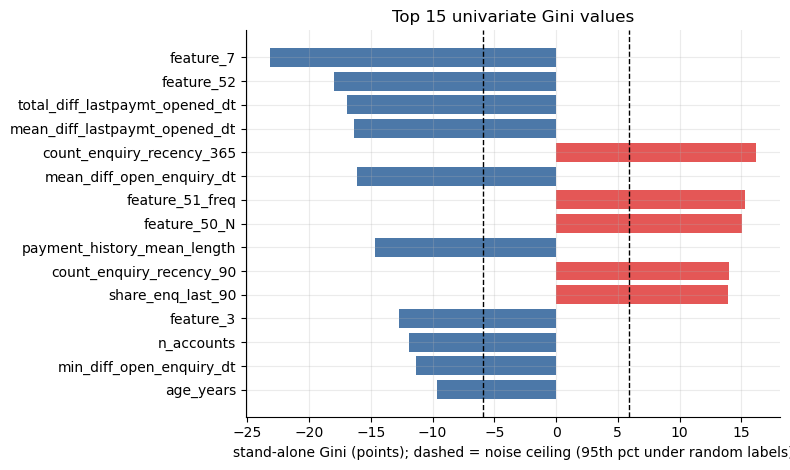

Features whose |Gini| exceeds the noise ceiling: 26 of 84


,univariate Gini
feature_7,-23.1
feature_52,-18.0
total_diff_lastpaymt_opened_dt,-17.0
mean_diff_lastpaymt_opened_dt,-16.4
count_enquiry_recency_365,16.2
mean_diff_open_enquiry_dt,-16.1
feature_51_freq,15.3
feature_50_N,15.0
payment_history_mean_length,-14.7
count_enquiry_recency_90,14.0


In [12]:
def gini_matrix(M, yv):
    # AUC of every column versus yv through rank sums (fast, vectorised)
    R = np.apply_along_axis(rankdata, 0, M)
    pos = yv == 1; n1, n0 = pos.sum(), (~pos).sum()
    auc = (R[pos].sum(axis=0) - n1 * (n1 + 1) / 2) / (n1 * n0)
    return 200 * (auc - 0.5)              # Gini in points

y = demo["Bad_label"].values.astype(int)
Xf = XA.fillna(XA.median())
uni = pd.Series(gini_matrix(Xf.values, y), index=Xf.columns)

rng = np.random.default_rng(SEED)
Rk = np.apply_along_axis(rankdata, 0, Xf.values)
null_max = []
for _ in range(200):
    yp = rng.permutation(y); pos = yp == 1; n1, n0 = pos.sum(), (~pos).sum()
    gi = 200 * ((Rk[pos].sum(axis=0) - n1 * (n1 + 1) / 2) / (n1 * n0) - 0.5)
    null_max.append(np.abs(gi).max())
thr95 = np.percentile(null_max, 95)
print("Largest |Gini| expected from pure noise among %d features: median %.1f, 95th percentile %.1f" % (len(Xf.columns), np.median(null_max), thr95))

top = uni.reindex(uni.abs().sort_values(ascending=False).index).head(15)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top.index[::-1], top.values[::-1], color=["#E45756" if v > 0 else "#4C78A8" for v in top.values[::-1]])
ax.axvline(thr95, color="k", ls="--", lw=1); ax.axvline(-thr95, color="k", ls="--", lw=1)
ax.set_xlabel("stand-alone Gini (points); dashed = noise ceiling (95th pct under random labels)")
ax.set_title("Top 15 univariate Gini values"); plt.tight_layout(); plt.show()
print("Features whose |Gini| exceeds the noise ceiling:", int((uni.abs() > thr95).sum()), "of", len(uni))
uni.reindex(uni.abs().sort_values(ascending=False).index).head(15).round(1).to_frame("univariate Gini")

**Finding.** Pure noise would produce a best-feature |Gini| of about 4 (95th percentile 5.9). **26 of 84 features beat that ceiling**. The leaders are `feature_7` (−23, an anonymised amount: higher values mean lower risk), `feature_52` (−18), the payment-timing gaps (`total_diff_lastpaymt_opened_dt` −17, `mean_diff_lastpaymt_opened_dt` −16) and the enquiry-intensity features (`count_enquiry_recency_365` +16, `mean_diff_open_enquiry_dt` −16). Signal is spread over many modest features, which suits a regularised ensemble.

## 4. Modelling

### 4.1 Design
* **Models:** regularised logistic regression (log-transform of skewed inputs + scaling), random forest, and a gradient-boosting model (`HistGradientBoostingClassifier`). Their predicted probabilities are averaged into an **ensemble** (the benchmark in the brief is also an ensemble).
* **Feature selection inside every fold:** a gradient-boosting model is fitted on the training part only, and its top-*K* features by **gain** (total loss reduction; this is scikit-learn's impurity-based importance, which is close to but not identical to XGBoost-style gain) feed the three models. The held-out part never influences which features are chosen.
* **Validation:** 5-fold stratified CV repeated twice (10 fits per setting, every customer scored once per repeat), plus a separate **out-of-time** test.
* **Metric:** Gini = 2·AUC − 1 (in points, matching the benchmark of 37.9) and decile rank ordering (decile 10 = highest predicted risk, as in the benchmark chart).

In [13]:
def gini(yv, s): return 200 * roc_auc_score(yv, s) - 100

class SkewLog(BaseEstimator, TransformerMixin):
    # log1p-transform non-negative columns whose skewness (on the training data) exceeds 2
    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.cols_ = [j for j in range(X.shape[1]) if X[:, j].min() >= 0 and abs(skew(X[:, j])) > 2]
        return self
    def transform(self, X):
        X = np.array(X, float); X[:, self.cols_] = np.log1p(X[:, self.cols_]); return X

def gain_importance(Xtr, ytr, seed):
    gb = GradientBoostingClassifier(n_estimators=80, learning_rate=0.08, max_depth=3, subsample=0.7,
                                    min_samples_leaf=30, max_features=0.5, random_state=seed).fit(Xtr, ytr)
    return gb.feature_importances_            # impurity-based gain, normalised to sum to 1

def make_models(seed):
    return {
        "LogReg":     Pipeline([("skew", SkewLog()), ("scale", StandardScaler()),
                                ("clf", LogisticRegression(C=0.05, max_iter=3000))]),
        "RandForest": RandomForestClassifier(n_estimators=120, min_samples_leaf=25, max_features=0.3,
                                             n_jobs=1, random_state=seed),
        "HistGB":     HistGradientBoostingClassifier(max_iter=150, learning_rate=0.04, max_depth=3, min_samples_leaf=40,
                                                     l2_regularization=5.0, random_state=seed),
    }
MODEL_NAMES = list(make_models(0))

def fit_fold(Xtr, ytr, Xte, ks, seed):
    # impute, rank features by gain on the TRAINING part only, then fit the three models for every K
    imp = SimpleImputer(strategy="median", keep_empty_features=True).fit(Xtr)
    Xtr, Xte = imp.transform(Xtr), imp.transform(Xte)
    gain = gain_importance(Xtr, ytr, seed)
    out = {}
    for k in ks:
        idx = np.argsort(-gain)[:k] if k else np.arange(Xtr.shape[1])
        out[k] = ({nm: m.fit(Xtr[:, idx], ytr).predict_proba(Xte[:, idx])[:, 1] for nm, m in make_models(seed).items()}, idx)
    return out

def ens(preds): return np.mean([preds[nm] for nm in MODEL_NAMES], axis=0)   # probability-average ensemble
print("Setup OK. Candidate features:", len(FEATURES), "| customers:", len(y), "| bads:", int(y.sum()))

Setup OK. Candidate features: 84 | customers: 23896 | bads: 1004


### 4.2 How many features? (K selected by gain inside each fold)
Four settings are compared: all 84 features, and the top 30, 20 and 10 by gain. This cell takes a few minutes.

In [14]:
t0 = time.time()
K_GRID = [None, 30, 20, 10]
Xv = XA.values
oof = {k: np.zeros((N_REPEATS, len(MODEL_NAMES), len(y))) for k in K_GRID}
picked = {k: np.zeros(Xv.shape[1]) for k in K_GRID}
fold_gini = {k: [] for k in K_GRID}

i = 0
for r in range(N_REPEATS):
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED + r)
    for tr, te in skf.split(Xv, y):
        res = fit_fold(Xv[tr], y[tr], Xv[te], K_GRID, SEED + i)
        for k, (preds, idx) in res.items():
            for j, nm in enumerate(MODEL_NAMES): oof[k][r, j, te] = preds[nm]
            picked[k][idx] += 1
            fold_gini[k].append(gini(y[te], ens(preds)))
        i += 1
    print("repeat %d/%d done (%.0f s)" % (r + 1, N_REPEATS, time.time() - t0))
sel_freq = {k: pd.Series(picked[k] / (N_REPEATS * N_FOLDS), index=XA.columns) for k in K_GRID}
print("Total CV time: %.0f s" % (time.time() - t0))

repeat 1/2 done (127 s)
repeat 2/2 done (255 s)
Total CV time: 255 s


,ensemble Gini,sd over repeats,mean fold Gini,sd over folds,LogReg,RandForest,HistGB
features (K),,,,,,,
all 84,36.7,0.2,36.8,3.4,34.3,33.2,35.6
30,36.8,0.2,36.8,3.5,35.8,33.6,35.4
20,35.6,0.3,35.7,3.4,34.3,32.9,34.4
10,32.6,0.3,32.6,4.2,30.9,29.7,31.7


Best setting: K = 30 (mean fold Gini 36.8, SE 1.1). Smallest K within one SE: K = 30


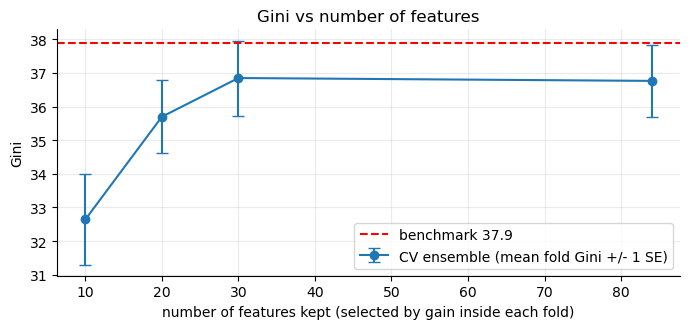

In [15]:
rows = []
for k in K_GRID:
    per_repeat = [gini(y, oof[k][r].mean(axis=0)) for r in range(N_REPEATS)]       # pooled out-of-fold Gini of the ensemble
    row = {"features (K)": "all %d" % len(FEATURES) if k is None else k,
           "ensemble Gini": np.mean(per_repeat), "sd over repeats": np.std(per_repeat, ddof=1),
           "mean fold Gini": np.mean(fold_gini[k]), "sd over folds": np.std(fold_gini[k], ddof=1)}
    for j, nm in enumerate(MODEL_NAMES): row[nm] = np.mean([gini(y, oof[k][r, j]) for r in range(N_REPEATS)])
    rows.append(row)
cv_tab = pd.DataFrame(rows).set_index("features (K)").round(1)
display(cv_tab)

# one-standard-error rule: smallest K whose mean fold Gini is within one standard error of the best
means = {k: np.mean(fold_gini[k]) for k in K_GRID}
ses   = {k: np.std(fold_gini[k], ddof=1) / np.sqrt(len(fold_gini[k])) for k in K_GRID}
best = max(K_GRID, key=lambda k: means[k])
cands = [k for k in K_GRID if means[k] >= means[best] - ses[best]]
K_FINAL = min([k for k in cands if k is not None], default=None)
if K_FINAL is None: K_FINAL = max([k for k in K_GRID if k is not None])
print("Best setting: K = %s (mean fold Gini %.1f, SE %.1f). Smallest K within one SE: K = %d" % (best, means[best], ses[best], K_FINAL))

fig, ax = plt.subplots(figsize=(7, 3.4))
xs = [len(FEATURES) if k is None else k for k in K_GRID]
ax.errorbar(xs, [means[k] for k in K_GRID], yerr=[ses[k] for k in K_GRID], marker="o", capsize=4, label="CV ensemble (mean fold Gini +/- 1 SE)")
ax.axhline(BENCHMARK_GINI, color="r", ls="--", label="benchmark 37.9")
ax.set_xlabel("number of features kept (selected by gain inside each fold)"); ax.set_ylabel("Gini"); ax.legend(); ax.set_title("Gini vs number of features")
plt.tight_layout(); plt.show()

**Finding.** All 84 features and the top 30 give practically the same Gini (about 36.8), the top 20 loses about 1 point and the top 10 loses 4. The one-standard-error rule picks **K = 30**. Logistic regression is the best single model (35.8), the gradient-boosting model is close (35.4), and the ensemble adds a little on top; the random forest is the weakest (33.6).

### 4.3 Final evaluation – Gini, uncertainty and rank ordering

In [16]:
oof_final = oof[K_FINAL]
P = oof_final.mean(axis=1)                                   # (repeats, n) ensemble probability per repeat
p_oof = P.mean(axis=0)                                       # averaged over repeats -> one score per customer
gini_rep = [gini(y, P[r]) for r in range(N_REPEATS)]
gini_pooled = np.mean(gini_rep)

rng = np.random.default_rng(SEED)
boot = []
for _ in range(300):
    ix = rng.integers(0, len(y), len(y))
    if 0 < y[ix].sum() < len(y): boot.append(gini(y[ix], P[0][ix]))
lo, hi = np.percentile(boot, [2.5, 97.5])
perm = [gini(rng.permutation(y), P[0]) for _ in range(500)]
se_hm = 200 * auc_se(gini_pooled / 200 + 0.5, int(y.sum()), int(len(y) - y.sum()))
RESULTS.update(gini=gini_pooled, gini_lo=lo, gini_hi=hi)

print("K = %d features | Gini per CV repeat: %s" % (K_FINAL, np.round(gini_rep, 1)))
print("Ensemble out-of-fold Gini: %.1f | Hanley-McNeil SE %.1f | bootstrap 95%% interval: %.1f to %.1f | benchmark: %.1f" % (gini_pooled, se_hm, lo, hi, BENCHMARK_GINI))
print("Share of bootstrap draws with Gini above the benchmark: %.0f%%" % (100 * np.mean(np.array(boot) > BENCHMARK_GINI)))
print("Label-shuffled Gini (500 runs): mean %.1f, max %.1f -> permutation p-value = %.3f" % (np.mean(perm), np.max(perm), (np.sum(np.array(perm) >= gini_pooled) + 1) / 501))
print("Single-model out-of-fold Gini:", {nm: round(np.mean([gini(y, oof_final[r, j]) for r in range(N_REPEATS)]), 1) for j, nm in enumerate(MODEL_NAMES)})

K = 30 features | Gini per CV repeat: [36.9 36.7]
Ensemble out-of-fold Gini: 36.8 | Hanley-McNeil SE 1.9 | bootstrap 95% interval: 33.8 to 40.1 | benchmark: 37.9
Share of bootstrap draws with Gini above the benchmark: 26%
Label-shuffled Gini (500 runs): mean -0.0, max 7.3 -> permutation p-value = 0.002
Single-model out-of-fold Gini: {'LogReg': np.float64(35.8), 'RandForest': np.float64(33.6), 'HistGB': np.float64(35.4)}


,customers,bads,bad_rate_%,benchmark_bad_rate_%,lift,cum_bads_captured_%
dec,,,,,,
10,2390,251,10.50,11.71,2.50,25.0
9,2389,184,7.70,8.05,1.83,43.3
8,2390,124,5.19,6.00,1.23,55.7
7,2389,105,4.40,3.96,1.05,66.1
6,2390,81,3.39,4.25,0.81,74.2
5,2389,84,3.52,3.66,0.84,82.6
4,2390,56,2.34,2.05,0.56,88.1
3,2389,56,2.34,2.05,0.56,93.7
2,2390,39,1.63,2.05,0.39,97.6


KS = 28.0 | rank-order breaks (decile 1->10 bad rate decreasing): 1 of 9 steps


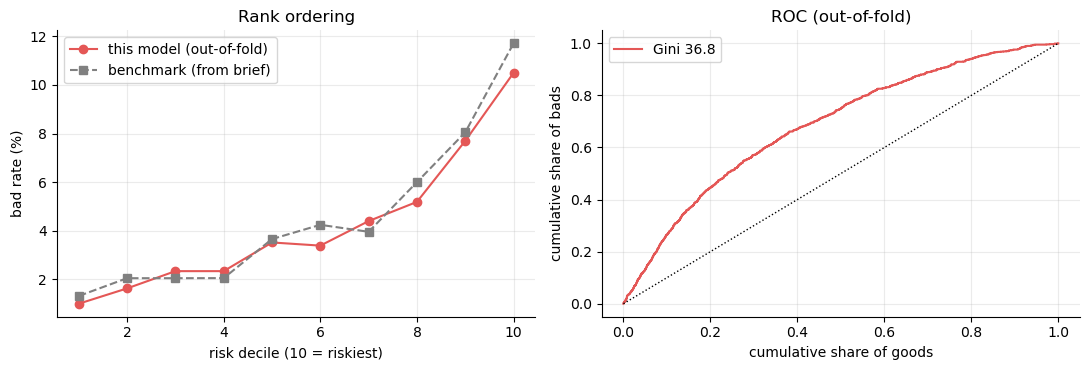

In [17]:
def decile_table(yv, score):
    # decile 10 = highest predicted risk (same orientation as the brief's chart)
    rk = pd.Series(score).rank(method="first")
    dec = pd.qcut(rk, 10, labels=False) + 1
    t = pd.DataFrame({"y": yv, "dec": dec}).groupby("dec").y.agg(customers="size", bads="sum", bad_rate="mean")
    t["bad_rate_%"] = (100 * t.bad_rate).round(2)
    t["benchmark_bad_rate_%"] = (100 * np.array(BENCHMARK_DECILES)).round(2)
    t["lift"] = (t.bad_rate / yv.mean()).round(2)
    cum = t.bads.sort_index(ascending=False).cumsum() / yv.sum()
    t["cum_bads_captured_%"] = (100 * cum.reindex(t.index)).round(1)
    return t[["customers", "bads", "bad_rate_%", "benchmark_bad_rate_%", "lift", "cum_bads_captured_%"]].sort_index(ascending=False)

dt_tab = decile_table(y, p_oof)
display(dt_tab)
rates = dt_tab["bad_rate_%"].sort_index().values                    # decile 1 ... 10
breaks = int((np.diff(rates) < 0).sum())
order_ = np.argsort(-p_oof); cb = np.cumsum(y[order_]) / y.sum(); cg = np.cumsum(1 - y[order_]) / (1 - y).sum()
ks = 100 * np.max(cb - cg)
RESULTS.update(top_dec=rates[-1], bot_dec=rates[0], breaks=breaks, ks=ks, top3=float(dt_tab["cum_bads_captured_%"].loc[8]))
print("KS = %.1f | rank-order breaks (decile 1->10 bad rate decreasing): %d of 9 steps" % (ks, breaks))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(1, 11)
ax[0].plot(x, rates, "o-", color="#E45756", label="this model (out-of-fold)")
ax[0].plot(x, 100 * np.array(BENCHMARK_DECILES), "s--", color="gray", label="benchmark (from brief)")
ax[0].set_xlabel("risk decile (10 = riskiest)"); ax[0].set_ylabel("bad rate (%)"); ax[0].set_title("Rank ordering"); ax[0].legend()
fpr = np.concatenate([[0], cg]); tpr = np.concatenate([[0], cb])
ax[1].plot(fpr, tpr, color="#E45756", label="Gini %.1f" % gini_pooled); ax[1].plot([0, 1], [0, 1], "k:", lw=1)
ax[1].set_xlabel("cumulative share of goods"); ax[1].set_ylabel("cumulative share of bads"); ax[1].set_title("ROC (out-of-fold)"); ax[1].legend()
plt.tight_layout(); plt.show()

**Result.** The out-of-fold ensemble Gini is **36.8** (bootstrap 95 % interval 33.8 to 40.1). The label-shuffle test confirms the model is far from chance (p ≈ 0.002). The benchmark's 37.9 lies inside the interval and 26 % of bootstrap draws exceed it, so on this data **the model is statistically indistinguishable from the benchmark, about 1 point lower on the point estimate**.

**Reading the result.** Rank ordering is good: bad rates fall from 10.5 % in decile 10 to 1.0 % in decile 1 with a single small inversion (decile 6, 3.39 %, sits below decile 5, 3.52 %). The benchmark has one inversion (deciles 6–7) and a flat stretch across deciles 2–4. At the safe end the model separates better than the benchmark (1.0 % vs 1.3 % in decile 1, 1.6 % vs 2.05 % in decile 2); at the risky end it is slightly flatter (10.5 % vs 11.7 % in decile 10). The riskiest three deciles hold 56 % of all bads, and KS is 28.0.

### 4.4 Out-of-time check

In [18]:
# Out-of-time check: fit on applications before 1 Nov 2015, score applications from 1 Nov 2015 onwards
cut = pd.Timestamp("2015-11-01")
tr = np.where(demo.app_dt < cut)[0]; te = np.where(demo.app_dt >= cut)[0]
res = fit_fold(Xv[tr], y[tr], Xv[te], [K_FINAL], SEED)
preds, idx = res[K_FINAL]
p_te = ens(preds)
g_oot = gini(y[te], p_te)
se_oot = 200 * auc_se(g_oot / 200 + 0.5, int(y[te].sum()), int(len(te) - y[te].sum()))
RESULTS.update(gini_oot=g_oot, oot_n=len(te), oot_bad=int(y[te].sum()), oot_se=se_oot)
print("Train: %d customers (%d bads) | Test: %d customers (%d bads)" % (len(tr), y[tr].sum(), len(te), y[te].sum()))
print("Out-of-time Gini: %.1f (+/- %.1f SE)   vs  benchmark %.1f" % (g_oot, se_oot, BENCHMARK_GINI))
print("Single models:", {nm: round(gini(y[te], preds[nm]), 1) for nm in MODEL_NAMES})
decile_table(y[te], p_te)

Train: 16180 customers (675 bads) | Test: 7716 customers (329 bads)
Out-of-time Gini: 33.9 (+/- 3.3 SE)   vs  benchmark 37.9
Single models: {'LogReg': np.float64(33.6), 'RandForest': np.float64(30.7), 'HistGB': np.float64(32.7)}


,customers,bads,bad_rate_%,benchmark_bad_rate_%,lift,cum_bads_captured_%
dec,,,,,,
10,772,68,8.81,11.71,2.07,20.7
9,771,53,6.87,8.05,1.61,36.8
8,772,47,6.09,6.00,1.43,51.1
7,771,44,5.71,3.96,1.34,64.4
6,772,32,4.15,4.25,0.97,74.2
5,771,31,4.02,3.66,0.94,83.6
4,772,17,2.20,2.05,0.52,88.8
3,771,17,2.20,2.05,0.52,93.9
2,772,10,1.30,2.05,0.30,97.0


**Finding.** Trained on 16,180 earlier applications and scored on 7,716 later ones (329 bads), the Gini is **33.9 ± 3.3**, about 3 points below the cross-validated figure, so some drift between vintages exists. The decile ordering holds without any inversion (two flat pairs: deciles 1–2 and 3–4). A production check should always include this out-of-time view.

## 5. Feature matrix – selected features with gain
Gain is the share of total loss reduction attributed to each feature by the gradient-boosting selection model (averaged over 10 seeds on the full data). The table also shows how often each feature was picked inside the CV folds, and cross-checks from the random forest and logistic regression.

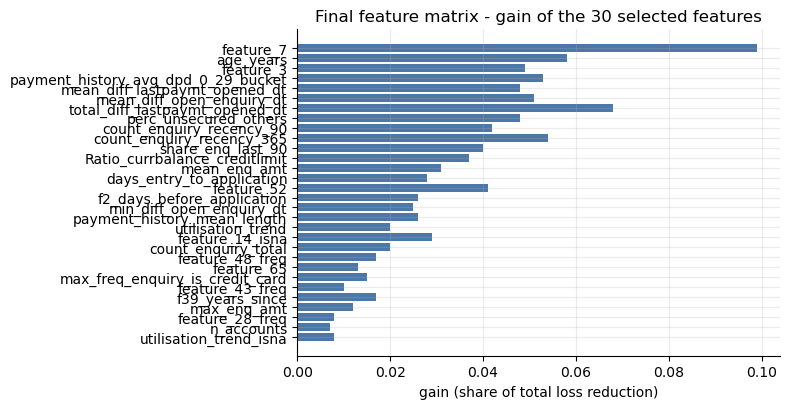

,"gain (selection, 10 seeds, full set)","gain (final GB, sums to 1)",random-forest importance,logistic coef (std. units),selected in % of CV folds,univariate Gini
feature,,,,,,
feature_7,0.096,0.099,0.071,-0.158,100.0,-23.129
age_years,0.056,0.058,0.060,0.003,100.0,-9.659
feature_3,0.054,0.049,0.049,-0.198,100.0,-12.750
payment_history_avg_dpd_0_29_bucket,0.048,0.053,0.026,-0.082,100.0,-4.038
mean_diff_lastpaymt_opened_dt,0.047,0.048,0.056,0.043,100.0,-16.379
mean_diff_open_enquiry_dt,0.047,0.051,0.057,0.032,100.0,-16.126
total_diff_lastpaymt_opened_dt,0.046,0.068,0.051,-0.072,100.0,-16.953
perc_unsecured_others,0.045,0.048,0.040,-0.100,100.0,-5.286
count_enquiry_recency_90,0.043,0.042,0.017,0.189,100.0,13.978


In [19]:
# Final feature matrix: gain averaged over 10 seeds on the full data, features chosen by gain (same rule as in the CV folds)
imp = SimpleImputer(strategy="median", keep_empty_features=True).fit(Xv)
Xi = imp.transform(Xv)
gains = np.mean([gain_importance(Xi, y, SEED + s) for s in range(10)], axis=0)
gain_s = pd.Series(gains, index=XA.columns).sort_values(ascending=False)
FINAL_FEATURES = gain_s.index[:K_FINAL].tolist()
Xs = Xi[:, [XA.columns.get_loc(c) for c in FINAL_FEATURES]]

final_models = {nm: m.fit(Xs, y) for nm, m in make_models(SEED).items()}
gb_final = GradientBoostingClassifier(n_estimators=120, learning_rate=0.05, max_depth=3, subsample=0.7,
                                      min_samples_leaf=30, max_features=0.5, random_state=SEED).fit(Xs, y)
fm = pd.DataFrame({
    "gain (selection, 10 seeds, full set)": gain_s.reindex(FINAL_FEATURES),
    "gain (final GB, sums to 1)":           pd.Series(gb_final.feature_importances_, index=FINAL_FEATURES),
    "random-forest importance":             pd.Series(final_models["RandForest"].feature_importances_, index=FINAL_FEATURES),
    "logistic coef (std. units)":           pd.Series(final_models["LogReg"].named_steps["clf"].coef_[0], index=FINAL_FEATURES),
    "selected in % of CV folds":            100 * sel_freq[K_FINAL].reindex(FINAL_FEATURES),
    "univariate Gini":                      uni.reindex(FINAL_FEATURES),
}).round(3)
fm.index.name = "feature"
RESULTS["final_features"] = FINAL_FEATURES

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(fm.index[::-1], fm["gain (final GB, sums to 1)"][::-1], color="#4C78A8")
ax.set_xlabel("gain (share of total loss reduction)"); ax.set_title("Final feature matrix - gain of the %d selected features" % K_FINAL)
plt.tight_layout(); plt.show()
fm

**Reading the matrix.** The top 22 features were picked in 100 % of CV folds, so the selection is stable. Gain is spread widely: no feature holds more than about 10 %. `feature_7` leads, followed by age, the bureau score (`feature_3`) and the account payment-history features (`payment_history_avg_dpd_0_29_bucket`, the payment-timing gaps, `Ratio_currbalance_creditlimit`), then the enquiry features. The last eight rows are less stable (for example `f39_years_since` was picked in 30 % of folds and `feature_43_freq` in 40 %) and could be dropped with little loss. `feature_14_isna` and `utilisation_trend_isna` are missing-value flags, so the *absence* of those fields is itself informative.

### 5.1 The brief's suggested features
The brief lists 12 candidate features with their gain in the bank's own model. All 12 are built here; the table compares the brief's gain with what they earn in this data.

In [20]:
# How did the 12 bureau features suggested in the brief fare in this run?
brief = {"payment_history_avg_dpd_0_29_bucket": 0.045653821, "total_diff_lastpaymt_opened_dt": 0.04083407, "min_months_last_30_plus": 0.038216344,
         "utilisation_trend": 0.037523553, "count_enquiry_recency_365": 0.036216624, "Ratio_currbalance_creditlimit": 0.035640536,
         "mean_diff_lastpaymt_opened_dt": 0.032185579, "mean_diff_open_enquiry_dt": 0.031057926, "payment_history_mean_length": 0.029258469,
         "max_freq_enquiry": 0.024501434, "count_enquiry_recency_90": 0.023796745, "perc_unsecured_others": 0.023428297}
alias = {"max_freq_enquiry": "max_freq_enquiry_is_credit_card"}
rows = []
for f, gbrief in brief.items():
    col = alias.get(f, f)
    rows.append({"feature": f, "gain in brief": gbrief, "built here": col in bureau.columns,
                 "coverage (%)": round(100 * bureau[col].notna().mean(), 1) if col in bureau.columns else 0.0,
                 "univariate Gini": round(float(uni.get(col, np.nan)), 1) if col in uni.index else np.nan,
                 "gain here (selection)": round(float(gain_s.get(col, np.nan)), 3) if col in gain_s.index else np.nan,
                 "in final model": col in FINAL_FEATURES})
pd.DataFrame(rows).set_index("feature")

,gain in brief,built here,coverage (%),univariate Gini,gain here (selection),in final model
feature,,,,,,
payment_history_avg_dpd_0_29_bucket,0.045654,True,100.0,-4.0,0.048,True
total_diff_lastpaymt_opened_dt,0.040834,True,99.8,-17.0,0.046,True
min_months_last_30_plus,0.038216,True,100.0,-1.3,0.003,False
utilisation_trend,0.037524,True,82.1,2.9,0.022,True
count_enquiry_recency_365,0.036217,True,99.5,16.2,0.040,True
Ratio_currbalance_creditlimit,0.035641,True,83.2,8.4,0.036,True
mean_diff_lastpaymt_opened_dt,0.032186,True,99.8,-16.4,0.047,True
mean_diff_open_enquiry_dt,0.031058,True,99.5,-16.1,0.047,True
payment_history_mean_length,0.029258,True,100.0,-14.7,0.022,True


**Result.** 11 of the 12 suggested features enter the final model. Only `min_months_last_30_plus` is left out: it has almost no gain here (0.003, stand-alone Gini −1.3), probably because few customers have a recent 30+ DPD history in this extract. Where this notebook's gain ranking differs from the brief's (for example the payment-timing gaps and enquiry recency rank higher here than `utilisation_trend`), it reflects this sample and my feature definitions, so I'd treat the brief's gains as a guide rather than a target.

## 6. From model to cred score
The out-of-fold ensemble probability is calibrated with a one-variable logistic regression and converted to a points score: **600 points at 50:1 good:bad odds, +40 points halves the bad odds**. Score bands should show a falling bad rate that matches the predicted PD.

,customers,bads,bad_rate_%,avg_predicted_PD_%
band,,,,
"(386.14000000000004, 502.741]",1195,124,10.38,12.10
"(502.741, 523.97]",2390,228,9.54,8.14
"(523.97, 550.671]",4779,261,5.46,5.56
"(550.671, 582.545]",7168,242,3.38,3.48
"(582.545, 608.532]",4779,110,2.30,2.16
"(608.532, 699.173]",3585,39,1.09,1.30


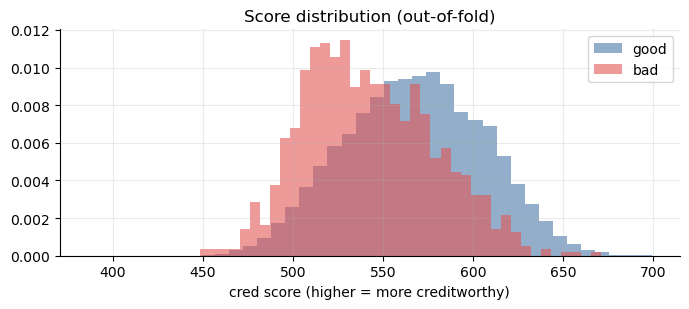

Sanity check of scoring function (in-sample, first 5 customers):


,pd,cred_score
0,0.029,577.892
1,0.052,542.136
2,0.038,560.698
3,0.022,593.191
4,0.035,566.402


In [21]:
from scipy.special import logit
# calibrate out-of-fold ensemble scores to probabilities of default, then scale to a credit score
lr = LogisticRegression(C=1e6).fit(logit(np.clip(p_oof, 1e-4, 1 - 1e-4)).reshape(-1, 1), y)
def pd_hat(p): return lr.predict_proba(logit(np.clip(p, 1e-4, 1 - 1e-4)).reshape(-1, 1))[:, 1]
PDO, BASE_SCORE, BASE_ODDS = 40, 600, 50          # 600 points at 50:1 good:bad odds, +40 points halves the bad odds
factor = PDO / np.log(2); offset = BASE_SCORE - factor * np.log(BASE_ODDS)
def to_score(p): pdv = np.clip(pd_hat(p), 1e-5, 1 - 1e-5); return offset + factor * np.log((1 - pdv) / pdv)

score = to_score(p_oof)
band = pd.qcut(score, [0, .05, .15, .35, .65, .85, 1], duplicates="drop")
bt = pd.DataFrame({"y": y, "pd": pd_hat(p_oof), "band": band}).groupby("band", observed=True).agg(
    customers=("y", "size"), bads=("y", "sum"), bad_rate=("y", "mean"), avg_predicted_PD=("pd", "mean"))
bt[["bad_rate", "avg_predicted_PD"]] = (100 * bt[["bad_rate", "avg_predicted_PD"]]).round(2)
bt = bt.rename(columns={"bad_rate": "bad_rate_%", "avg_predicted_PD": "avg_predicted_PD_%"})
display(bt)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(score[y == 0], bins=40, alpha=.6, density=True, label="good", color="#4C78A8")
ax.hist(score[y == 1], bins=40, alpha=.6, density=True, label="bad", color="#E45756")
ax.set_xlabel("cred score (higher = more creditworthy)"); ax.legend(); ax.set_title("Score distribution (out-of-fold)")
plt.tight_layout(); plt.show()

# Scoring function for new customers: fit on all data, same feature list
def score_new(X_new_df):
    Xn = imp.transform(X_new_df[XA.columns].values)[:, [XA.columns.get_loc(c) for c in FINAL_FEATURES]]
    p = np.mean([m.predict_proba(Xn)[:, 1] for m in final_models.values()], axis=0)
    return pd.DataFrame({"pd": pd_hat(p), "cred_score": to_score(p)}, index=X_new_df.index)
print("Sanity check of scoring function (in-sample, first 5 customers):")
score_new(XA.head()).round(3)

**Result.** Observed bad rates fall steadily from 10.4 % in the lowest band to 1.1 % in the highest, and calibration is close (predicted PD 12.1 % → 1.3 %). `score_new()` scores any new customer row built with the same feature pipeline. The scale (600 / 50:1 / PDO 40) is a convention to agree with the bank.

## 7. Conclusions, caveats and next steps

**What was found and decided**
1. The three tables are clean and fully linked (23,896 customers, 4.2 % bad). Data exploration led to dropping roughly 30 unusable columns (constant, sparse, duplicate, identifier, high-cardinality, messy-date and decision-process fields) and transforming the rest (Section 1.4).
2. `dt_opened` is used only as a reference date and for the out-of-time split, never as a feature.
3. Signal is modest and spread across many features; 26 of 84 beat a permutation noise ceiling. The leaders are an anonymised amount (`feature_7`), age, the bureau score (`feature_3`), account payment-history features and enquiry intensity.
4. The final model is an ensemble of three regularised models on the **top 30 features by gain**, selected inside each CV fold.

**Result versus the benchmark**

| | This notebook | Benchmark |
|---|---|---|
| Gini, cross-validated | **36.8** (95 % interval 33.8–40.1) | 37.9 |
| Gini, out-of-time | **33.9** ± 3.3 | – |
| Top / bottom decile bad rate | 10.5 % / 1.0 % | 11.7 % / 1.3 % |
| Decile order breaks (of 9 steps) | 1 | 1 (plus flat deciles 2–4) |

The model is within sampling noise of the benchmark Gini and separates the safest customers better, but I can't claim it beats the benchmark on this evidence.

**Caveats**
* **The Gini gap to the benchmark is inside the margin of error** (standard error about ±1.9). The benchmark uses 66 features; this model uses 30 selected from 84, built from my own reading of the brief's definitions.
* **Two assumptions need confirming:** the purpose codes counted as "unsecured / others" (`{0, 5, 6, 10, 12}`) and that purpose `10` is a credit-card enquiry. I also assumed the most recent month comes first in `paymenthistory1`.
* The out-of-time Gini (33.9) is lower than cross-validation (36.8), which suggests some vintage drift.
* The scale of the cred score is a convention, not a bank standard.

**Next steps**
1. Confirm the assumptions above with the bank, especially the payment-history ordering and purpose codes, since they drive the strongest bureau features.
2. Try to close the remaining gap: richer payment-history features (trend, recency of worst delinquency, per-account type), account-type splits, and hyper-parameter tuning, then re-check out-of-time.
3. Validate the final model out-of-time on newer data before any use in decisioning.
4. Keep credentials out of notebooks and documents: the project brief contains live database credentials in plain text and should be rotated and shared more carefully.